In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import pandas as pd
import os

# Path to your fixed Stage 1 split
SPLIT_CSV = "/content/drive/MyDrive/Projectwork/Betel Leaf/betel_leaf_stratified_split.csv"

# Load split
df = pd.read_csv(SPLIT_CSV)

print("Total images:", len(df))
print(df["split"].value_counts())
print("\nClass distribution:")
print(pd.crosstab(df["split"], df["class"]))

Total images: 743
split
train         520
test          112
validation    111
Name: count, dtype: int64

Class distribution:
class       bacterial  fungal  healthy
split                                 
test               37      38       37
train             172     175      173
validation         37      37       37


In [ ]:
# Use only train + validation for the annotation pilot
pilot_pool = df[df["split"].isin(["train", "validation"])].copy()

# Fixed random seed for reproducibility
pilot_df = (
    pilot_pool
    .groupby("class", group_keys=False)
    .apply(
        lambda x: x.sample(
            n={"bacterial": 12, "fungal": 12, "healthy": 6}[x.name],
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("Pilot size:", len(pilot_df))
print("\nPilot class distribution:")
print(pilot_df["class"].value_counts())

print("\nPilot split distribution:")
print(pilot_df["split"].value_counts())

Pilot size: 30

Pilot class distribution:
class
bacterial    12
fungal       12
healthy       6
Name: count, dtype: int64

Pilot split distribution:
split
train         22
validation     8
Name: count, dtype: int64


/tmp/ipykernel_822/3982866169.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [ ]:
PILOT_CSV = "/content/drive/MyDrive/Projectwork/Betel Leaf/Stage3_Annotation_Pilot.csv"

pilot_df.to_csv(PILOT_CSV, index=False)

print("Saved pilot list to:")
print(PILOT_CSV)

Saved pilot list to:
/content/drive/MyDrive/Projectwork/Betel Leaf/Stage3_Annotation_Pilot.csv


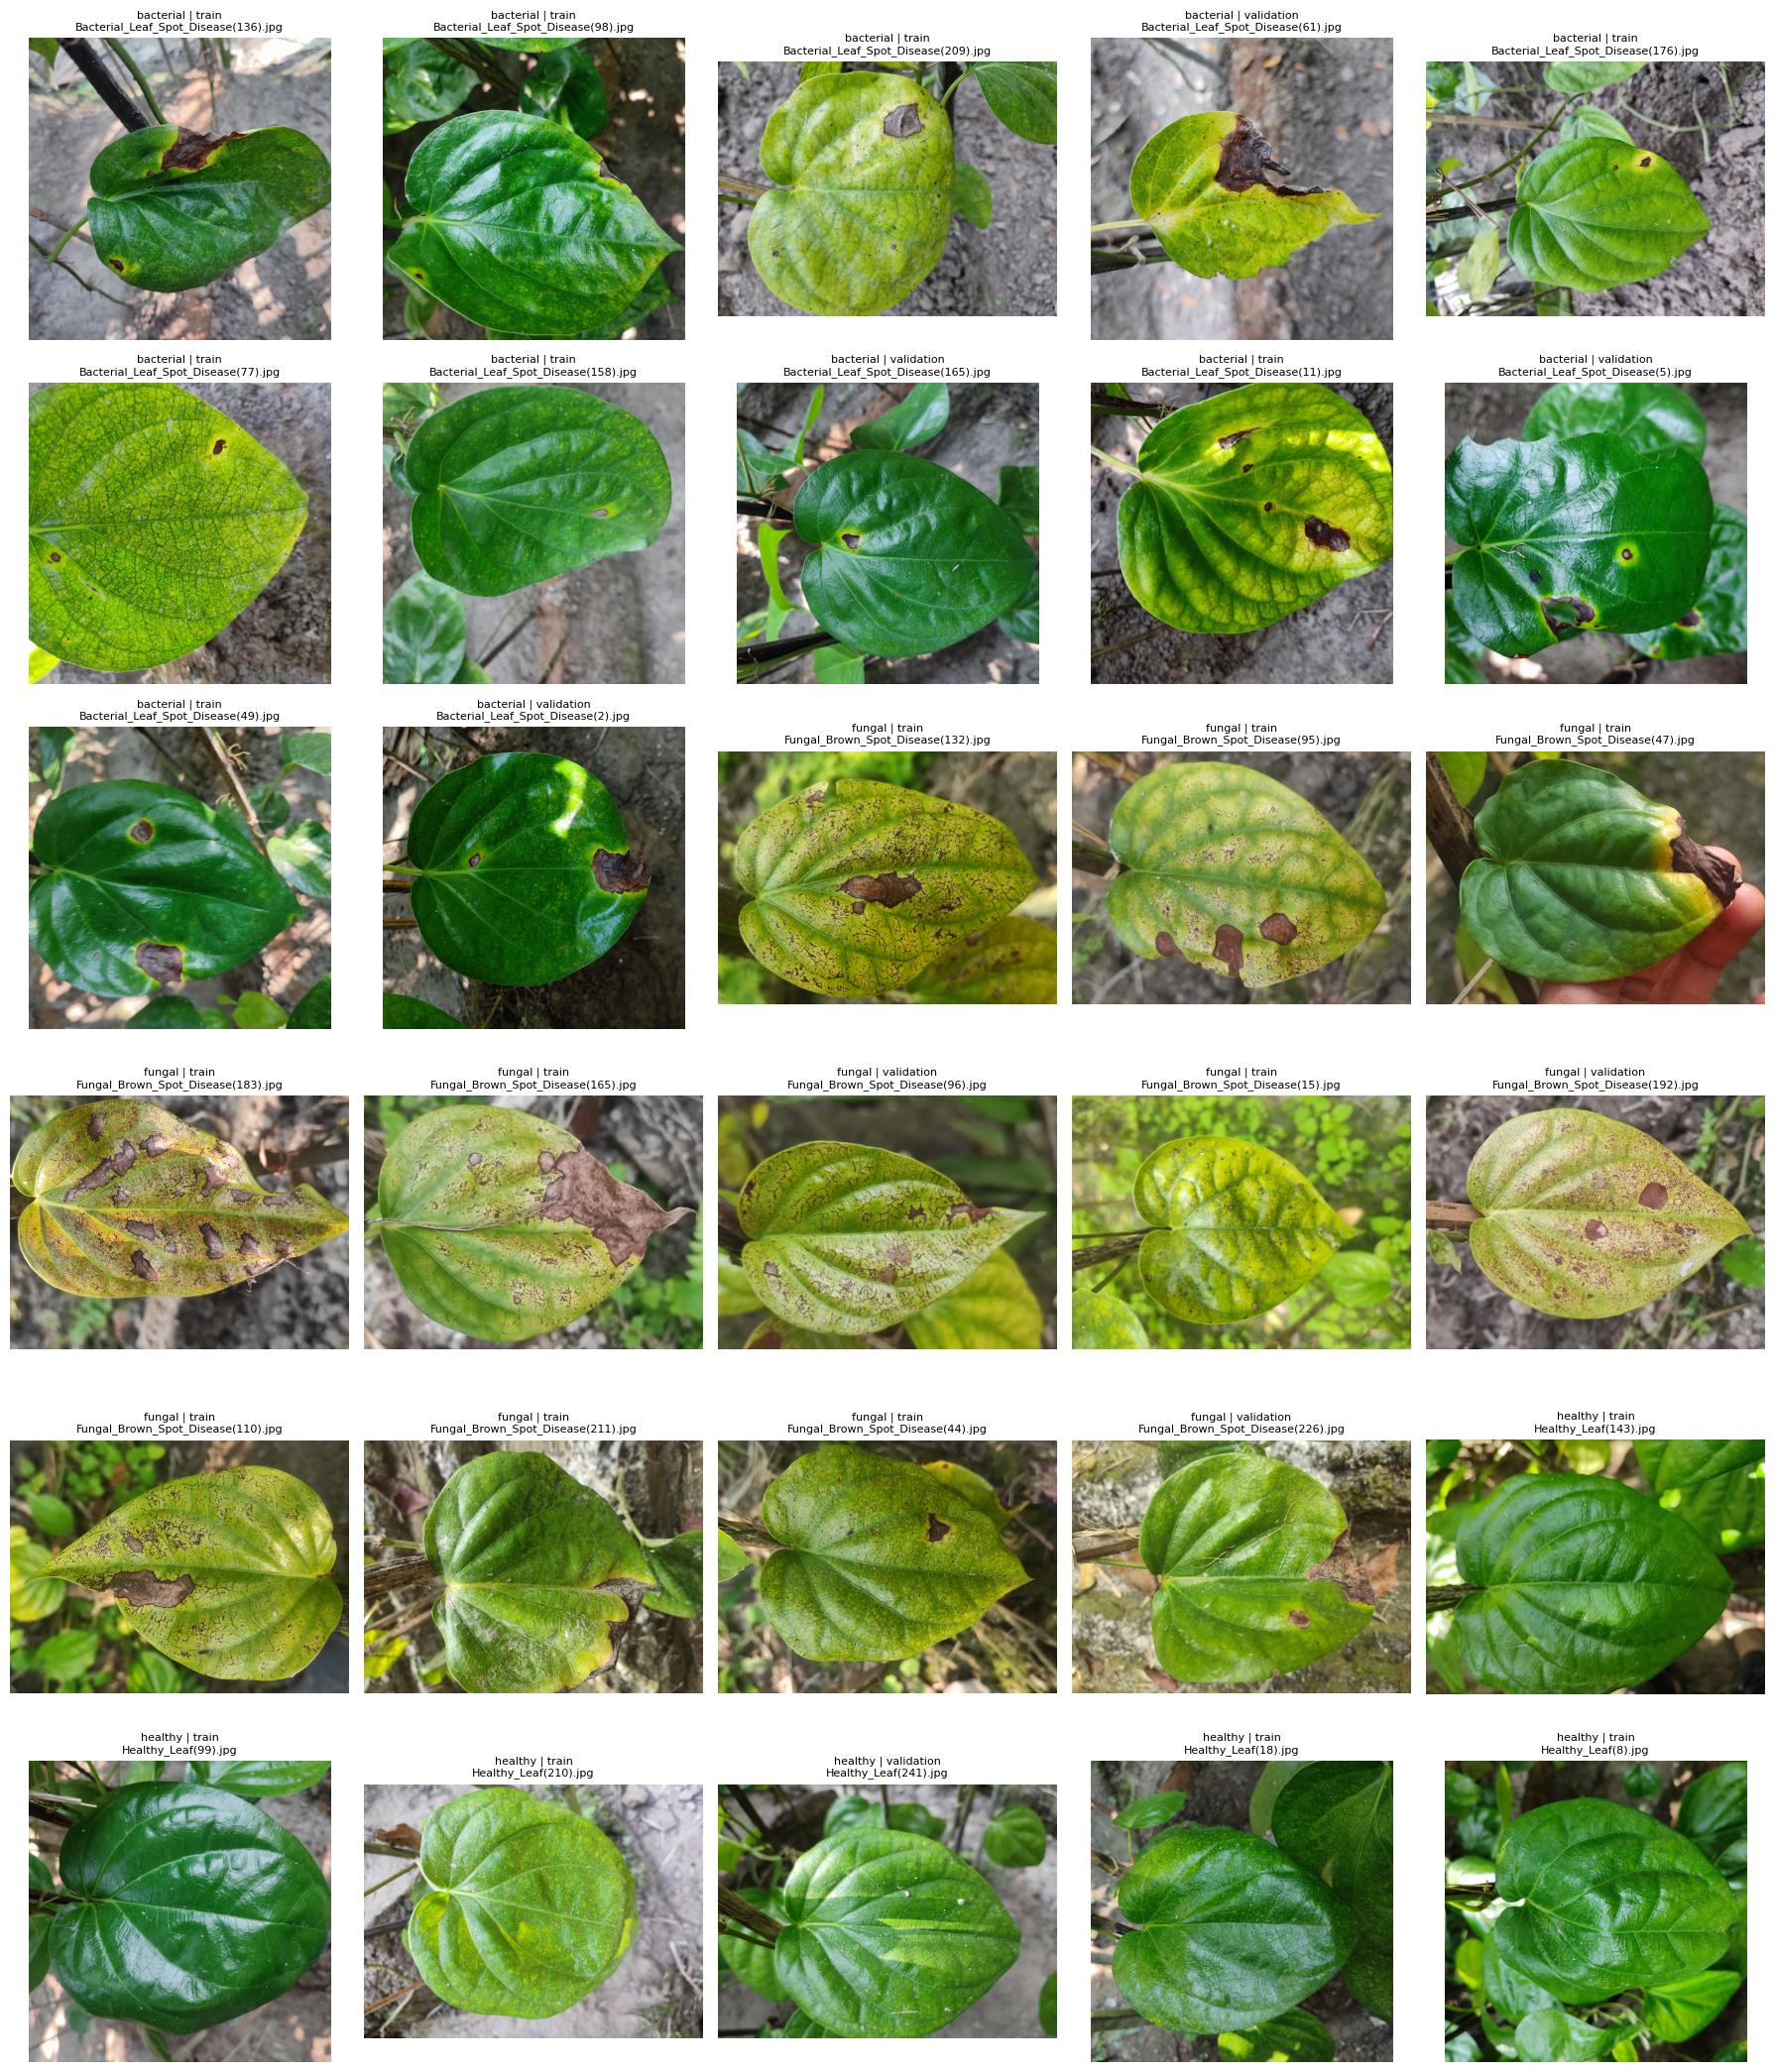

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

n = len(pilot_df)
cols = 5
rows = math.ceil(n / cols)

plt.figure(figsize=(18, rows * 3.5))

for i, (_, row) in enumerate(pilot_df.iterrows()):
    img = Image.open(row["path"]).convert("RGB")

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(img)
    ax.set_title(
        f"{row['class']} | {row['split']}\n{row['filename']}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

SPLIT_CSV = "/content/drive/MyDrive/Projectwork/Betel Leaf/betel_leaf_stratified_split.csv"

df = pd.read_csv(SPLIT_CSV)

# Find the suspicious entry
x = df[df["filename"] == "Fungal_Brown_Spot_Disease(10).jpg"]

print(x.to_string(index=False))

                         filename                                                                                              path  class split
Fungal_Brown_Spot_Disease(10).jpg /content/drive/MyDrive/Projectwork/Betel Leaf/Betel Leaf/fungal/Fungal_Brown_Spot_Disease(10).jpg fungal  test


In [ ]:
# Check the exact path recorded in the CSV
for _, row in x.iterrows():
    print("CSV path:")
    print(row["path"])
    print()
    print("Does this exact path exist?")
    print(os.path.exists(row["path"]))

CSV path:
/content/drive/MyDrive/Projectwork/Betel Leaf/Betel Leaf/fungal/Fungal_Brown_Spot_Disease(10).jpg

Does this exact path exist?
True


In [ ]:
FUNGAL_DIR = "/content/drive/MyDrive/Projectwork/Betel Leaf/Betel Leaf/fungal"

files = os.listdir(FUNGAL_DIR)

matches = [
    f for f in files
    if "Fungal_Brown_Spot_Disease" in f
]

print("Matching files in fungal folder:")
for f in sorted(matches):
    print(f)

print("\nTotal fungal files:", len(files))

Matching files in fungal folder:
Fungal_Brown_Spot_Disease(1).jpg
Fungal_Brown_Spot_Disease(10).jpg
Fungal_Brown_Spot_Disease(100).jpg
Fungal_Brown_Spot_Disease(101).jpg
Fungal_Brown_Spot_Disease(102).jpg
Fungal_Brown_Spot_Disease(103).jpg
Fungal_Brown_Spot_Disease(104).jpg
Fungal_Brown_Spot_Disease(105).jpg
Fungal_Brown_Spot_Disease(106).jpg
Fungal_Brown_Spot_Disease(107).jpg
Fungal_Brown_Spot_Disease(108).jpg
Fungal_Brown_Spot_Disease(109).jpg
Fungal_Brown_Spot_Disease(11).jpg
Fungal_Brown_Spot_Disease(110).jpg
Fungal_Brown_Spot_Disease(111).jpg
Fungal_Brown_Spot_Disease(112).jpg
Fungal_Brown_Spot_Disease(113).jpg
Fungal_Brown_Spot_Disease(114).jpg
Fungal_Brown_Spot_Disease(115).jpg
Fungal_Brown_Spot_Disease(116).jpg
Fungal_Brown_Spot_Disease(117).jpg
Fungal_Brown_Spot_Disease(118).jpg
Fungal_Brown_Spot_Disease(119).jpg
Fungal_Brown_Spot_Disease(12).jpg
Fungal_Brown_Spot_Disease(120).jpg
Fungal_Brown_Spot_Disease(121).jpg
Fungal_Brown_Spot_Disease(122).jpg
Fungal_Brown_Spot_Disease(1